# CYP Fragment Dataset Comparison

## Objective

Compare the prevalence of CYP-relevant chemical groups
between the scored and blind challenge datasets.

Research questions:
1. Which fragments are more prevalent in the blind dataset?
2. Which fragments are less prevalent?
3. Could differences in fragment distributions affect
   model generalization?

This analysis measures distribution differences, not
predictive feature importance.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../data")

with open(DATA_DIR / "cyp_fragment_data.json") as f:
    data = json.load(f)

df = pd.read_csv(DATA_DIR / "cyp_features.csv")

print("Molecules:", len(df))
print("Available datasets:", data["datasets"])

Molecules: 39505
Available datasets: ['challenge/blind', 'challenge/test', 'challenge/train', 'challenge/val', 'family/CYP11B1', 'family/CYP11B2', 'family/CYP17A1', 'family/CYP19A1', 'family/CYP1A1', 'family/CYP1A2', 'family/CYP1B1', 'family/CYP24A1', 'family/CYP2A6', 'family/CYP2B6', 'family/CYP2C19', 'family/CYP2C8', 'family/CYP2C9', 'family/CYP2D6', 'family/CYP2E1', 'family/CYP3A4', 'family/CYP3A5', 'family/CYP4A11', 'family/CYP4F2', 'family/TBXAS1', 'qhts/CYP1A2', 'qhts/CYP2C19', 'qhts/CYP2C9', 'qhts/CYP2D6', 'qhts/CYP3A4']


In [3]:
# Dataset indices from the JSON
scored_ids = [
    data["datasets"].index(name)
    for name in [
        "challenge/train",
        "challenge/val",
        "challenge/test"
    ]
]

blind_id = data["datasets"].index("challenge/blind")

# Assign dataset membership
df["scored"] = [
    any(i in membership for i in scored_ids)
    for membership in data["membership"]
]

df["blind"] = [
    blind_id in membership
    for membership in data["membership"]
]

print("Scored molecules:", df["scored"].sum())
print("Blind molecules:", df["blind"].sum())

Scored molecules: 4901
Blind molecules: 748


In [4]:
# Get CYP feature columns
feature_cols = [
    frag["id"]
    for frag in data["fragments"]
    if frag["set"] == "cyp"
]

# Calculate prevalence in each dataset
scored_prevalence = (
    df.loc[df["scored"], feature_cols].mean() * 100
)

blind_prevalence = (
    df.loc[df["blind"], feature_cols].mean() * 100
)

comparison = pd.DataFrame({
    "Scored (%)": scored_prevalence,
    "Blind (%)": blind_prevalence
})

# Positive means more common in blind
comparison["Difference (pp)"] = (
    comparison["Blind (%)"] - comparison["Scored (%)"]
)

comparison = comparison.sort_values(
    "Difference (pp)",
    ascending=False
)

display(comparison.round(2))

,Scored (%),Blind (%),Difference (pp)
aryl halide,26.59,35.43,8.84
imidazole,10.55,18.85,8.30
pyridine,26.02,31.28,5.27
sulfonamide,11.81,15.78,3.96
furan / thiophene,8.67,10.70,2.02
methylenedioxyphenyl,1.02,2.41,1.39
carboxylic acid,3.29,4.28,0.99
nitro,0.45,1.07,0.62
steroid core,0.31,0.00,-0.31
phenol,3.86,3.48,-0.38


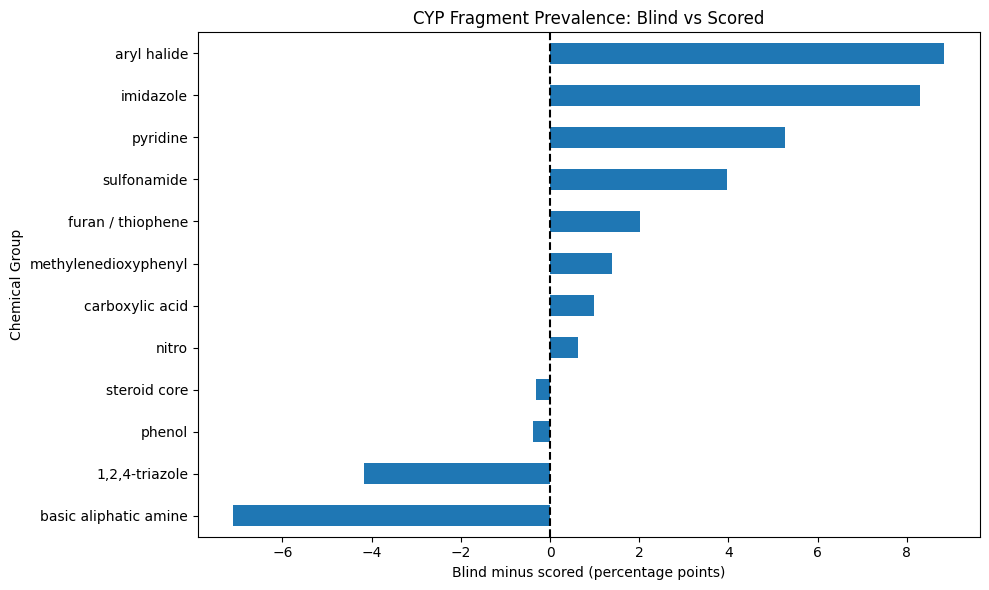

In [5]:
plt.figure(figsize=(10, 6))

comparison["Difference (pp)"].sort_values().plot(
    kind="barh"
)

plt.axvline(0, color="black", linestyle="--")

plt.title("CYP Fragment Prevalence: Blind vs Scored")
plt.xlabel("Blind minus scored (percentage points)")
plt.ylabel("Chemical Group")

plt.tight_layout()
plt.show()

## Findings

The dataset contains 4,901 scored molecules and 748 blind molecules. Comparing the prevalence of 12 CYP-relevant chemical groups revealed several differences between the two datasets.

Aryl halide (+8.84 percentage points), imidazole (+8.30), and pyridine (+5.27) were more prevalent in the blind dataset. In contrast, basic aliphatic amine (−7.10) and 1,2,4-triazole (−4.17) were less prevalent.

These differences suggest a shift in chemical group distributions between the scored and blind datasets. Such shifts may affect how well a model trained on scored molecules generalizes to unseen blind molecules.

However, prevalence differences alone do not indicate whether a chemical group is predictive of CYP inhibition.

## Next Steps

The next step is to connect the fragment features to measured CYP inhibition values and investigate whether certain chemical groups are associated with stronger or weaker inhibition.

Subsequently, machine learning experiments can determine whether adding these fragment indicators improves prediction accuracy beyond standard molecular features.